In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [3]:
df = pd.read_csv(
    "dataset/student/student-mat.csv",
    sep=";"
)

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
print("Shape:", df.shape)

df.info()

Shape: (395, 33)
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null  

In [5]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [6]:
X = df.drop("G3", axis=1)

y = df["G3"]

In [7]:
X = pd.get_dummies(
    X,
    drop_first=True
)

In [8]:
cleaned_df = X.copy()

cleaned_df["G3"] = y

cleaned_df.to_csv(
    "student_mat_regression_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

Cleaned dataset saved.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)


Training: (316, 41)
Testing : (79, 41)


In [10]:
models = {
    "Linear Regression": LinearRegression(),
    
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [11]:
results = []

for name, model in models.items():

    model.fit(
        X_train,
        y_train
    )

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    results.append([
        name,
        mae,
        rmse,
        r2
    ])

In [12]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ]
)

results_df.sort_values(
    by="R2",
    ascending=False
)

,Model,MAE,RMSE,R2
2,Random Forest,1.164557,1.948773,0.814791
1,Decision Tree,1.139241,2.050008,0.795049
0,Linear Regression,1.646666,2.378370,0.724134


C:\Users\comda\AppData\Local\Temp\ipykernel_16360\363451972.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


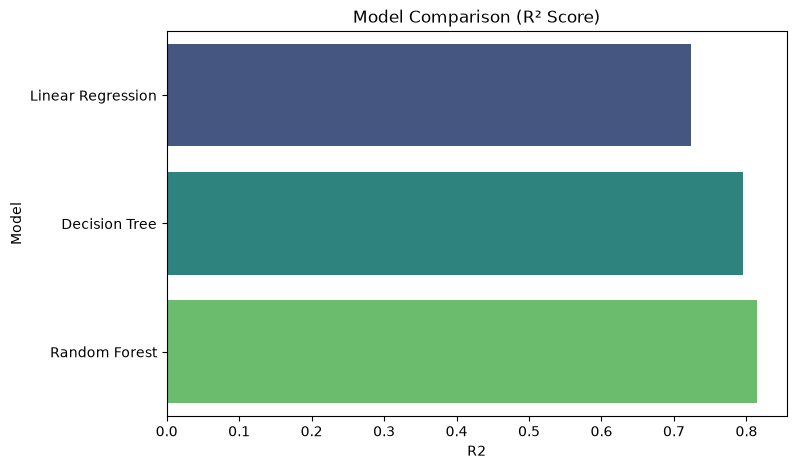

In [13]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="R2",
    y="Model",
    palette="viridis"
)

plt.title(
    "Model Comparison (R² Score)"
)

plt.show()

In [14]:
best_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

best_model.fit(
    X_train,
    y_train
)

y_pred = best_model.predict(
    X_test
)

In [15]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE :", round(mae,3))
print("RMSE:", round(rmse,3))
print("R²  :", round(r2,3))

MAE : 1.165
RMSE: 1.949
R²  : 0.815


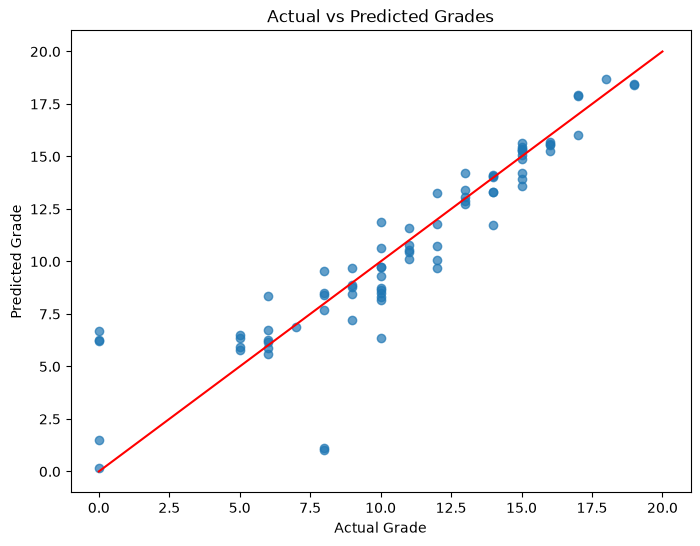

In [16]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.plot(
    [0,20],
    [0,20],
    color="red"
)

plt.xlabel("Actual Grade")

plt.ylabel(
    "Predicted Grade"
)

plt.title(
    "Actual vs Predicted Grades"
)

plt.show()

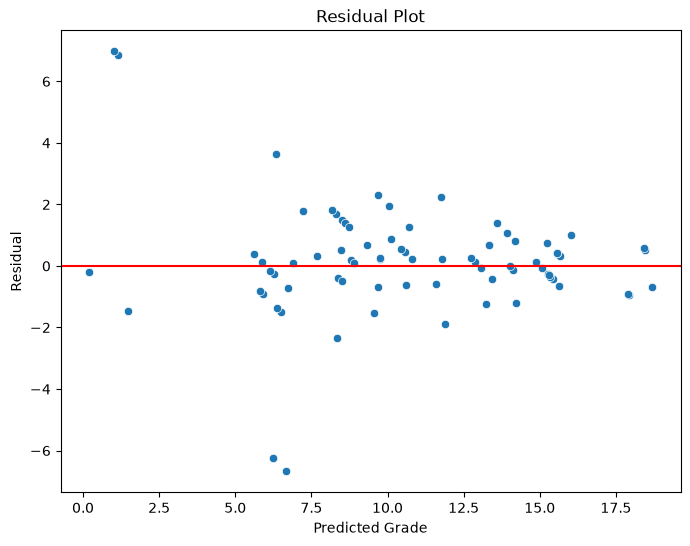

In [17]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(
    y=0,
    color='red'
)

plt.xlabel(
    "Predicted Grade"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Residual Plot"
)

plt.show()

In [18]:
importance = pd.DataFrame({
    "Feature":
    X.columns,

    "Importance":
    best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
14,G2,0.793254
12,absences,0.110093
28,reason_home,0.021086
0,age,0.010433
13,G1,0.005979
6,famrel,0.005260
8,goout,0.004840
11,health,0.004190
36,activities_yes,0.003933
4,studytime,0.003697


C:\Users\comda\AppData\Local\Temp\ipykernel_16360\786910224.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


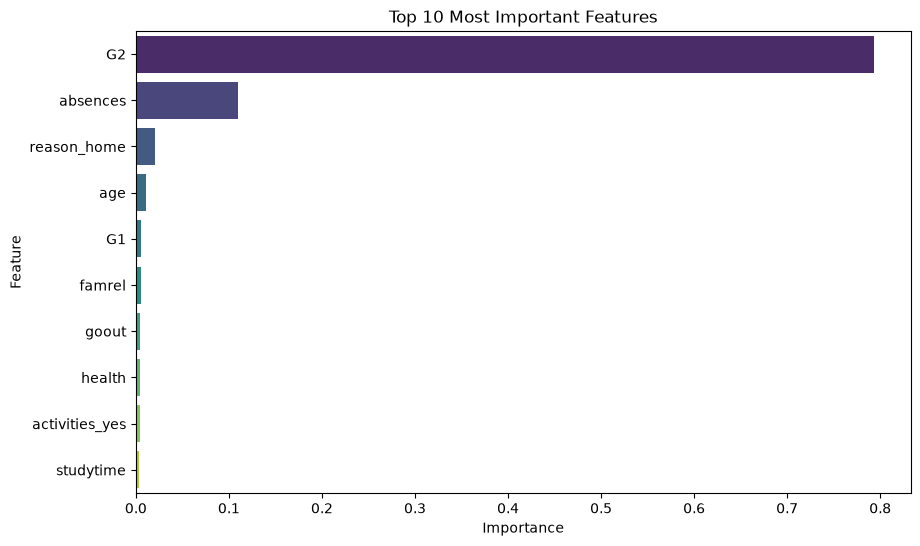

In [19]:
top10 = importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title(
    "Top 10 Most Important Features"
)

plt.show()

In [20]:
sample_student = X.iloc[[0]]

In [21]:
predicted_grade = best_model.predict(
    sample_student
)

print(
    "Predicted Final Grade:",
    round(predicted_grade[0],2)
)

Predicted Final Grade: 6.27


In [22]:
# %%
joblib.dump(best_model, "student_grade_regression_model.pkl")

joblib.dump(
    X.columns.tolist(),
    "model_columns.pkl"
)

['model_columns.pkl']

In [23]:
# %%
comparison = pd.DataFrame({
    "Actual Grade": y_test,
    "Predicted Grade": np.round(y_pred, 2)
})

comparison.head(20)

,Actual Grade,Predicted Grade
78,10,8.32
371,12,11.78
248,5,6.50
55,10,9.76
390,9,8.80
223,13,12.86
42,18,18.70
234,6,6.72
316,0,6.68
116,14,13.33
